In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Ajouter le dossier racine du projet au chemin de recherche Python
racine_projet = Path.cwd().parent
sys.path.insert(0, str(racine_projet))

from api.api_client import fetch_dataset

df = fetch_dataset("meteo")

print(df.head())

   identifiant_station   latitude  longitude      date_observation  \
0             75106001  48.844833     2.3385  2026-11-05T20:00:00Z   
1             75106001  48.844833     2.3385  2026-11-05T19:00:00Z   
2             75106001  48.844833     2.3385  2026-11-05T18:00:00Z   
3             75106001  48.844833     2.3385  2026-11-05T17:00:00Z   
4             75106001  48.844833     2.3385  2026-11-05T16:00:00Z   

   temperature_celsius  point_rosee_celsius  humidite_relative_pct  \
0                 10.9                  NaN                    NaN   
1                 11.1                  NaN                    NaN   
2                 11.2                  NaN                    NaN   
3                 11.1                  NaN                    NaN   
4                 11.5                  NaN                    NaN   

   direction_vent_deg  vitesse_vent_ms  visibilite_m  pression_station_pa  \
0                 NaN              NaN           NaN                  NaN   
1   

In [2]:
# ============================================================
# 1. CHARGEMENT DU DATASET
# ============================================================

# Conversion des colonnes temporelles
colonnes_dates = [
    "reference_time",
    "insert_time",
    "validity_time"
]

for col in colonnes_dates:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], utc=True)

In [3]:
# ============================================================
# 2. INFORMATIONS GENERALES
# ============================================================

print("\n========== INFORMATIONS GENERALES ==========")

print("Dimensions du dataset :", df.shape)

print("\nTypes des variables :")
print(df.dtypes)

print("\nInformations générales :")
df.info()

print("\nAperçu du dataset :")
print(df.head())


========== INFORMATIONS GENERALES ==========
Dimensions du dataset : (701, 12)

Types des variables :
identifiant_station        int64
latitude                 float64
longitude                float64
date_observation             str
temperature_celsius      float64
point_rosee_celsius      float64
humidite_relative_pct    float64
direction_vent_deg       float64
vitesse_vent_ms          float64
visibilite_m             float64
pression_station_pa      float64
pression_mer_pa          float64
dtype: object

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 701 entries, 0 to 700
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   identifiant_station    701 non-null    int64  
 1   latitude               701 non-null    float64
 2   longitude              701 non-null    float64
 3   date_observation       701 non-null    str    
 4   temperature_celsius    701 non-null    float64
 5 

In [4]:
# ============================================================
# 3. STATISTIQUES DESCRIPTIVES
# ============================================================

print("\n========== STATISTIQUES DESCRIPTIVES ==========")

# Sélection des variables numériques
df_num = df.select_dtypes(include=np.number)

# Statistiques classiques
stats = df_num.describe().T

# Ajout de statistiques complémentaires
stats["median"] = df_num.median()
stats["variance"] = df_num.var()
stats["skewness"] = df_num.skew()
stats["kurtosis"] = df_num.kurt()

print(stats.round(3))

# Export des statistiques
stats.to_csv("statistiques_descriptives.csv")


========== STATISTIQUES DESCRIPTIVES ==========
                       count          mean       std           min  \
identifiant_station    701.0  7.511118e+07  3763.760  7.510600e+07   
latitude               701.0  4.884700e+01     0.021  4.882200e+01   
longitude              701.0  2.316000e+00     0.041  2.234000e+00   
temperature_celsius    701.0  8.500000e+00     2.039  2.000000e+00   
point_rosee_celsius    234.0  4.348000e+00     2.491 -1.000000e-01   
humidite_relative_pct  234.0  7.573500e+01    11.667  5.100000e+01   
direction_vent_deg     349.0  6.086000e+01    53.082  0.000000e+00   
vitesse_vent_ms        349.0  4.600000e+00     2.827  0.000000e+00   
visibilite_m           117.0  1.771410e+04  3398.844  4.840000e+03   
pression_station_pa    117.0  1.017406e+05   317.743  1.012400e+05   
pression_mer_pa        117.0  1.027018e+05   316.959  1.021900e+05   

                                25%           50%           75%           max  \
identifiant_station    7.5107

In [ ]:
"""
On peut remarquer que plusieurs catégories partagent le même compte
--> On peut en déduire que toutes les stations météos ne disposent pas forcément du même outillage de capteurs

Ainsi il y aurait 4 types de stations :
    Type 1 :
        - Thermomètre
    Type 2 :
        - Thermomètre (température)
        - Anémomètre (vitesse & direction du vent)
    Type 3 :
        - Thermomètre (température)
        - Anémomètre (vitesse & direction du vent)
        - Hygromètre (humidité et point de rosée)
    Type 4 :
        - Thermomètre (température)
        - Anémomètre (vitesse & direction du vent)
        - Hygromètre (humidité et point de rosée)
        - Baromètre (pression)
        - Diffusiomètre (visibilité)

Ces catégories seront à prendre en compte dans l'évaluation de la qualité des données
"""

In [24]:
# ============================================================
# 3.1 AJOUT DES CATEGORIES TYPE ONE-HOT ENCODER


# Classification des stations selon les capteurs disponibles

capteurs = {
    "temperature": 4,
    "vent": 6,
    "humidite": 8,
    "pression_visibilite": 11
}

for ligne in df_num.rows:
    print(ligne)
    nb_col_not_null = 0
    for col in df_num.columns:
        nb_col_not_null += ligne[col].notna().sum()

    cpt_type_station = 0
    for capt in capteurs:
        cpt_type_station += 1
        type_station = "type_" + str(cpt_type_station)

        if nb_col_not_null == capteurs[capt]:
            ligne[type_station] = 1
        else :
            ligne[type_station] = 0

# Vérification du nombre d'observations par catégorie
print(df_num.head())

print(df_num[["type_1", "type_2", "type_3", "type_4"]].sum())


AttributeError: 'DataFrame' object has no attribute 'rows'


========== VALEURS MANQUANTES ==========
                       nb_valeurs_manquantes  pourcentage_manquant
pression_mer_pa                          584                 83.31
visibilite_m                             584                 83.31
pression_station_pa                      584                 83.31
point_rosee_celsius                      467                 66.62
humidite_relative_pct                    467                 66.62
direction_vent_deg                       352                 50.21
vitesse_vent_ms                          352                 50.21
identifiant_station                        0                  0.00
date_observation                           0                  0.00
longitude                                  0                  0.00
latitude                                   0                  0.00
temperature_celsius                        0                  0.00


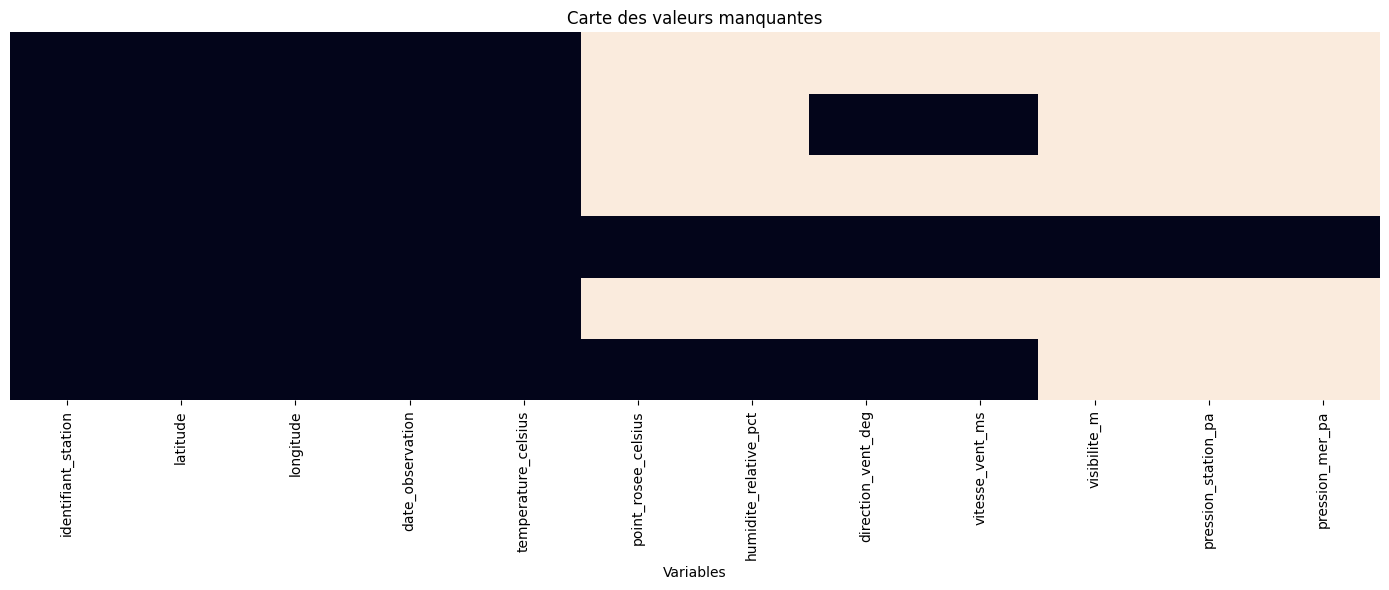

In [5]:
# ============================================================
# 4. ANALYSE DES VALEURS MANQUANTES
# ============================================================

print("\n========== VALEURS MANQUANTES ==========")

missing = pd.DataFrame({
    "nb_valeurs_manquantes": df.isnull().sum(),
    "pourcentage_manquant": (
        df.isnull().mean() * 100
    )
})

missing = missing.sort_values(
    by="pourcentage_manquant",
    ascending=False
)

print(missing.round(2))

# Visualisation des valeurs manquantes
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Carte des valeurs manquantes")
plt.xlabel("Variables")
plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# 5. ANALYSE DES TEMPERATURES
# ============================================================

temperature_cols = [
    "temperature_celsius",
    "temperature_max_celsius",
    "temperature_min_celsius",
    "point_rosee_celsius"
]

temperature_cols = [
    col for col in temperature_cols
    if col in df.columns
]

print("\n========== STATISTIQUES DES TEMPERATURES ==========")

print(
    df[temperature_cols].describe().T.round(2)
)


========== STATISTIQUES DES TEMPERATURES ==========
                     count  mean   std  min   25%  50%  75%   max
temperature_celsius  701.0  8.50  2.04  2.0  7.10  8.7  9.7  14.6
point_rosee_celsius  234.0  4.35  2.49 -0.1  2.42  4.5  6.4   9.4


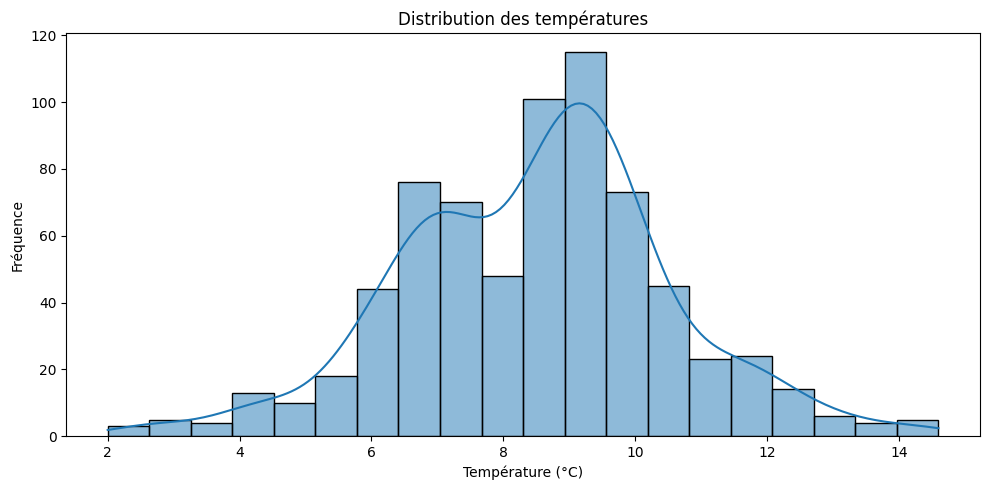

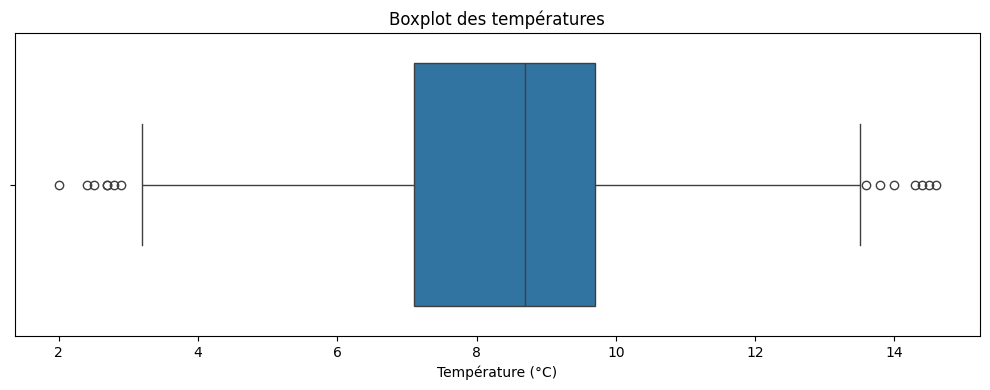

In [7]:
# ============================================================
# 6. DISTRIBUTION DES TEMPERATURES
# ============================================================

if "temperature_celsius" in df.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        df["temperature_celsius"].dropna(),
        bins=20,
        kde=True
    )

    plt.title("Distribution des températures")
    plt.xlabel("Température (°C)")
    plt.ylabel("Fréquence")

    plt.tight_layout()
    plt.show()

    # Boxplot
    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df["temperature_celsius"]
    )

    plt.title("Boxplot des températures")
    plt.xlabel("Température (°C)")

    plt.tight_layout()
    plt.show()

In [8]:
# ============================================================
# 7. EVOLUTION TEMPORELLE
# ============================================================

if (
    "reference_time" in df.columns
    and "temperature_celsius" in df.columns
):

    df = df.sort_values("reference_time")

    plt.figure(figsize=(14, 6))

    plt.plot(
        df["reference_time"],
        df["temperature_celsius"],
        marker="o",
        linestyle="-"
    )

    plt.title("Evolution temporelle de la température")
    plt.xlabel("Date et heure")
    plt.ylabel("Température (°C)")

    plt.xticks(rotation=45)
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [9]:
# ============================================================
# 8. DETECTION DES VALEURS ABERRANTES (IQR)
# ============================================================

print("\n========== DETECTION DES OUTLIERS ==========")

for col in df_num.columns:

    serie = df[col].dropna()

    if serie.empty:
        continue

    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = serie[
        (serie < borne_inf) |
        (serie > borne_sup)
    ]

    print(f"\nVariable : {col}")
    print("Borne inférieure :", round(borne_inf, 3))
    print("Borne supérieure :", round(borne_sup, 3))
    print("Nombre d'outliers :", len(outliers))


========== DETECTION DES OUTLIERS ==========

Variable : identifiant_station
Borne inférieure : 75096502.0
Borne supérieure : 75124510.0
Nombre d'outliers : 0

Variable : latitude
Borne inférieure : 48.767
Borne supérieure : 48.913
Nombre d'outliers : 0

Variable : longitude
Borne inférieure : 2.229
Borne supérieure : 2.404
Nombre d'outliers : 0

Variable : temperature_celsius
Borne inférieure : 3.2
Borne supérieure : 13.6
Nombre d'outliers : 14

Variable : point_rosee_celsius
Borne inférieure : -3.538
Borne supérieure : 12.362
Nombre d'outliers : 0

Variable : humidite_relative_pct
Borne inférieure : 36.0
Borne supérieure : 116.0
Nombre d'outliers : 0

Variable : direction_vent_deg
Borne inférieure : -30.0
Borne supérieure : 130.0
Nombre d'outliers : 10

Variable : vitesse_vent_ms
Borne inférieure : -2.8
Borne supérieure : 11.6
Nombre d'outliers : 1

Variable : visibilite_m
Borne inférieure : 9450.0
Borne supérieure : 26330.0
Nombre d'outliers : 4

Variable : pression_station_pa
Born


========== MATRICE DE CORRELATION ==========
                       identifiant_station  latitude  longitude  \
identifiant_station                   1.00     -0.38      -0.37   
latitude                             -0.38      1.00      -0.14   
longitude                            -0.37     -0.14       1.00   
temperature_celsius                   0.07     -0.05       0.21   
point_rosee_celsius                   0.02      0.02      -0.02   
humidite_relative_pct                 0.13      0.13      -0.13   
direction_vent_deg                   -0.01      0.02      -0.01   
vitesse_vent_ms                      -0.83      0.38       0.19   
visibilite_m                           NaN       NaN        NaN   
pression_station_pa                    NaN       NaN        NaN   
pression_mer_pa                        NaN       NaN        NaN   

                       temperature_celsius  point_rosee_celsius  \
identifiant_station                   0.07                 0.02   
latitude       

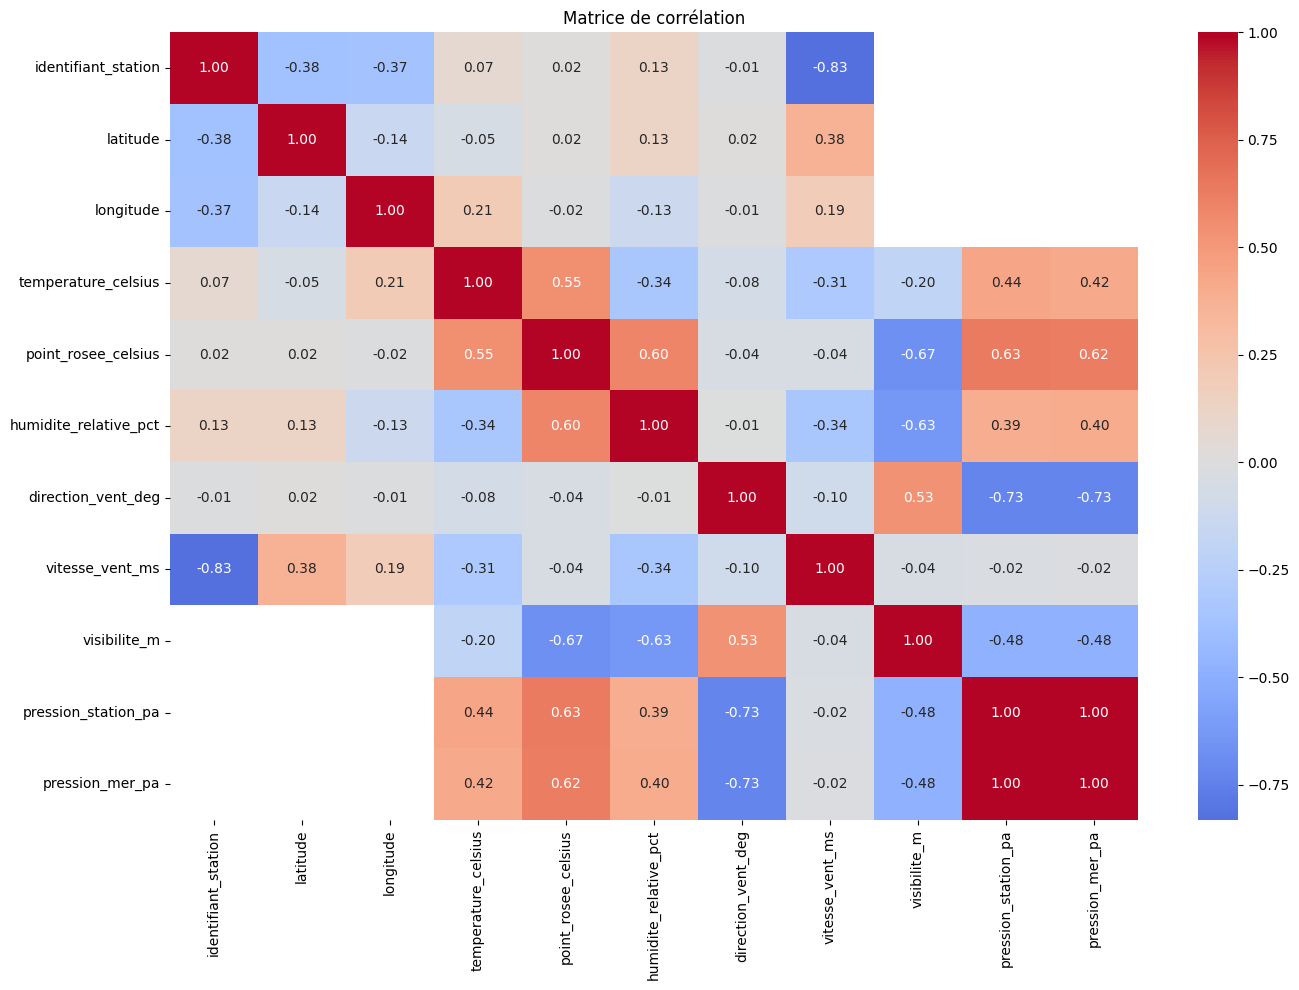

In [10]:
# ============================================================
# 9. MATRICE DE CORRELATION
# ============================================================

# On retire les variables numériques constantes
df_corr = df_num.loc[
    :, df_num.nunique(dropna=True) > 1
]

if not df_corr.empty:

    correlation = df_corr.corr()

    print("\n========== MATRICE DE CORRELATION ==========")

    print(correlation.round(2))

    plt.figure(figsize=(14, 10))

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        center=0
    )

    plt.title("Matrice de corrélation")

    plt.tight_layout()
    plt.show()

In [11]:
# ============================================================
# 10. EXPORT DES RESULTATS
# ============================================================

missing.to_csv("valeurs_manquantes.csv")

print("\nAnalyse statistique terminée.")



Analyse statistique terminée.
